### 11_ElasticNet_Base_MLU

Cible : TousAge_allergie_urgences, le taux de passages aux urgences pour allergie, tous âges, par semaine et par département **de la semaine suivante**..


**Split chronologique:** 

2021–2022 : train -  apprentissage du modèle et des prétraitements.
2023 : valid - comparaison des premiers essais, choix des variables et réglages.
2024 : test - évaluation finale, après avoir arrêté les choix.

0. Moyenne globale de toutes semaines et tout departements confondus (by Mathilde)

1. Model de persistance (2021-2022 train /2023: valid/ 2024 test:)
prévoir le même taux que le dernier connu.

//et pas à expliquer le taux d'une semaine avec les données de la meme semaine, car cela repondrai à la question suivante:  « Peut-on estimer le taux de passages aux urgences pour allergie d’une semaine à partir des conditions observées pendant cette même semaine ? » (elle ne mesure pas la capacité à prévoir la semaine suivante, puisque les conditions réelles de semaine 11 ne sont pas connues à la fin de semaine 10) //

2. on rajoute un lag de 1 semaine pour pouvoir predire de la semaine suivante:
2021-2022 train /2023: valid/ 2024 test
(2.a)  sans historique de taux sanitaire: 
- variables explicatives disponibles à la semaine 10, et calendrire semaine 11 --> pour predire taux de la semaine 11

ie: À la fin de la semaine 10, on utilise les informations disponibles jusqu’à cette date pour prévoir le taux de la semaine 11. donc utiliser la météo et la pollution de la semaine 10, à ne pas utiliser les observations réelles de la semaine 11 

(2.b) - avec historique sanitaire 
- variables explicatives + historique de taux sanitaires jusqu'à la semaine 10 pour predire la semaine 11


Le découpage des lignes reste identique. Ce sont les colonnes données au modèle qui changent.

Pour la première ligne :
- Sans historique sanitaire : le modèle reçoit la température 15 et doit prévoir 800.
- Avec historique sanitaire : il reçoit la température 15 et le taux connu 700, pour prévoir le même 800. La réponse à prévoir est toujours la même. On ajoute seulement une information dans le deuxième essai.

A . Preparation de la base commun

EN COMMUN:

- cible : taux d’allergie aux urgences, tous âges, de la semaine suivante 
- variables explicatives: retirer les preriodes de rafales et tout les precipitations sauf 3h, les autres colonnes cibles

- calendrier: encodage commun des periodes - on garde pour l'instant celui de Mathilde
- departement: encodage categorielle ? (vraiment necessaire si on traite en str?)

## 1 Importer les outils et charger le fichier


In [2]:
# import packages 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Pretraitement, preprocessing modelisation
from sklearn import model_selection, preprocessing

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import ElasticNet, LinearRegression

from sklearn.model_selection import cross_val_predict, cross_val_score, cross_validate, train_test_split


#Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


#others
from pathlib import Path
import joblib
from sklearn.pipeline import Pipeline






In [3]:
#Chargement de fichier commun

# fichier fusionné par le groupe (07_Merge)
df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={'code_dept': str})

display(df.info())

df.columns.tolist()

cible = 'TousAge_allergie_urgences'
df[cible].describe()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

None

count    19968.000000
mean       744.778217
std        315.852165
min          0.000000
25%        538.838945
50%        699.809373
75%        900.156926
max       3636.363636
Name: TousAge_allergie_urgences, dtype: float64

Supression des colonnes

In [4]:
# suppression des colonnes autre cible que taux_urgence_allergie_tous_age,  les categories Ntop et Npop

colonnes_supprimer = ["65plus_allergie_urgences", "0_14_allergie_urgences" , "15_64_allergie_urgences",
                         "0_14_asthme_urgences","15_64_asthme_urgences",  "TousAge_asthme_urgences", "65plus_asthme_urgences",
                         "0an_bronchiolite_urgences","TousAge_allergie_hospitalisation", "65plus_allergie_hospitalisation",
                         "0_14_allergie_hospitalisation", "15_64_allergie_hospitalisation", "0_14_asthme_hospitalisation", 
                         "15_64_asthme_hospitalisation", "TousAge_asthme_hospitalisation", "65plus_asthme_hospitalisation", 
                         "0an_bronchiolite_hospitalisation", "nom_dep","Ntop_Maladie_Respi_Chronique_tsage_9", 'Npop_Maladie_Respi_Chronique_tsage_9', 
                         'Ntop_Maladie_Respi_Chronique_0-14_9', 'Ntop_Maladie_Respi_Chronique_15-64_9',
                         'Ntop_Maladie_Respi_Chronique_65+_9', 'Npop_Maladie_Respi_Chronique_0-14_9', 'Npop_Maladie_Respi_Chronique_15-64_9',
                         'Npop_Maladie_Respi_Chronique_65+_9']

df_work = df.drop(columns = colonnes_supprimer).copy()

df_work.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

In [5]:
# inventaire des colonnes


# Colonnes numériques
cols_num = df_work.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = df_work.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = df_work.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 52 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs

C:\Users\monik\AppData\Local\Temp\ipykernel_35112\1234785755.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = df_work.select_dtypes(include=["object", "category"]).columns.tolist()


In [6]:
resume = pd.DataFrame({
    "Type": df_work.dtypes,
    "Valeurs uniques": df_work.nunique(),
    "NaN (%)": df_work.isna().mean() * 100
})

display(resume)

,Type,Valeurs uniques,NaN (%)
date_semaine,str,208,0.0
code_dept,str,96,0.0
As in PM10,float64,10176,0.0
BaP in PM10,float64,5416,0.0
Cd in PM10,float64,5959,0.0
Ni in PM10,float64,11344,0.0
Pb in PM10,float64,12174,0.0
NO2,float64,10564,0.0
O3,float64,7459,0.0
PM10,float64,4555,0.0


## 2 Encodage cyclic par sin /cos
On conserve le code qui extrait `annee` et `semaine` du libellé `2021-S01`.
Le tri se fait sur département, année et numéro de semaine. Aucune conversion en date n’est nécessaire.
Les blocs de quatre semaines sont calculés comme dans son notebook.


In [7]:

# extraire l'année et semaine,
df_work["annee"] = df_work["date_semaine"].str[:4].astype(int)
df_work["semaine"] = df_work["date_semaine"].str[-2:].astype(int)

# Représenter la saisonnalité annuelle par un cycle de 52 semaines

df_work["semaine_sin"] = np.sin(2*np.pi*df_work["semaine"]/52)
df_work["semaine_cos"] = np.cos(2*np.pi*df_work["semaine"]/52)

#trier par année, semaine et departement
df_work = df_work.sort_values(["code_dept", "annee", "semaine"]).reset_index(drop=True)
assert not df_work.duplicated(["code_dept", "annee", "semaine"]).any()                      #verifier si il y a des doublons

In [8]:
df_work.head()

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee,semaine,semaine_sin,semaine_cos
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,1,0.120537,0.992709
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,2,0.239316,0.970942
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,3,0.354605,0.935016
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,4,0.464723,0.885456
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,5,0.568065,0.822984


## 3 Créer le taux à prévoir
Sur une ligne de semaine X, on garde les informations de semaine X et on place le taux de semaine X+1 dans une nouvelle colonne `taux_suivant`.
`shift(-1)` place la réponse future sur la ligne des informations courantes. Il est calculé séparément par département pour ne pas mélanger leurs séries.

`taux_connu` reprend le taux courant. **On suppose ici qu’il est déjà publié à la date de prévision.** Si ce n’est pas le cas, il faudra utiliser un taux plus ancien.


In [11]:
#creation des nouvelles colonnes pour les dates cibles et taux suivante 

df_work["taux_suivant"] = df_work.groupby("code_dept")[cible].shift(-1)       #regroupe les observations par departement et recupere la valeur de la ligne suivante dans la meme departement
df_work["taux_connu"] = df[cible]

# On rapproche aussi le libellé et le calendrier de la semaine à prévoir.
df_work["semaine_a_prevoir"] = df_work.groupby("code_dept")["date_semaine"].shift(-1)
df_work["annee_cible"] = df_work.groupby("code_dept")["annee"].shift(-1)
df_work["semaine_cible"] = df_work.groupby("code_dept")["semaine"].shift(-1)
df_work["semaine_cible_sin"] = df_work.groupby("code_dept")["semaine_sin"].shift(-1)
df_work["semaine_cible_cos"] = df_work.groupby("code_dept")["semaine_cos"].shift(-1)

In [13]:
# La dernière semaine n’a pas de réponse suivante : on retire cette ligne, sans remplacer la cible par zéro.
data = df_work.dropna(subset=["taux_suivant", "taux_connu"]).copy()

data["annee_cible"] = data["annee_cible"].astype(int)
data["semaine_cible"] = data["semaine_cible"].astype(int)
data["semaine_cible_sin"] = data["semaine_cible_sin"].astype(float)
data["semaine_cible_cos"] = data["semaine_cible_cos"].astype(float)

data[["code_dept", "date_semaine", "semaine_a_prevoir", "taux_connu", "taux_suivant"]].head()


,code_dept,date_semaine,semaine_a_prevoir,taux_connu,taux_suivant
0,01,2021-S01,2021-S02,446.144041,254.939452
1,01,2021-S02,2021-S03,254.939452,361.228176
2,01,2021-S03,2021-S04,361.228176,531.600709
3,01,2021-S04,2021-S05,531.600709,289.184500
4,01,2021-S05,2021-S06,289.184500,637.348630


## Corrélations décalés
Par exemple : température de semaine 10 avec taux d’allergie de semaine 11. Faites cette exploration sur le train, par département

In [14]:
#Selection des variables
# Sélection des colonnes numériques
num_cols = data.select_dtypes(include="number").columns

# Colonnes à exclure de l'analyse
exclure = [
    "annee", "semaine", "periode",
    "annee_cible", "semaine_cible", "periode_cible",
    "taux_connu"
]

# Exclure aussi les colonnes issues du encoding
exclure += [col for col in num_cols if col.startswith("periode_")]

# Conserver les variables explicatives pertinentes
variables = [col for col in num_cols if col not in exclure]

In [15]:

# Calcul des deux matrices de correlation
corr_pearson = data[variables].corr(method='pearson')

print("Corrélations de Pearson :")
display(corr_pearson)


corr_spearman = data[variables].corr(method='spearman')
print("Corrélations de Spearman :")
display(corr_spearman)

Corrélations de Pearson :


,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,PM2.5,SO2,...,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,semaine_sin,semaine_cos,taux_suivant,semaine_cible_sin,semaine_cible_cos
As in PM10,1.000000,0.317030,0.488677,0.419315,0.701347,0.315936,-0.158667,0.219387,0.276207,0.198015,...,1.306695e-01,-7.875019e-04,-6.156715e-02,1.394518e-02,1.357992e-01,9.963673e-02,2.056336e-01,-0.128919,1.235853e-01,1.920524e-01
BaP in PM10,0.317030,1.000000,0.266693,0.111181,0.288258,0.445215,-0.436027,0.252448,0.415952,0.164705,...,1.771461e-02,-2.540164e-02,-3.322515e-02,-3.438267e-02,1.689784e-02,6.198327e-02,4.771177e-01,-0.139693,1.187714e-01,4.660983e-01
Cd in PM10,0.488677,0.266693,1.000000,0.135781,0.548236,0.359182,-0.201290,0.213711,0.279997,0.115136,...,-3.682360e-02,4.978524e-02,-3.829706e-02,-1.024835e-03,-3.094096e-02,1.376899e-01,2.625705e-01,-0.057571,1.681939e-01,2.439613e-01
Ni in PM10,0.419315,0.111181,0.135781,1.000000,0.411231,0.078025,-0.006958,0.040570,0.034867,0.142526,...,1.680930e-01,1.342242e-02,-5.263796e-02,-1.021284e-02,1.878687e-01,-6.649580e-03,-2.258717e-02,-0.009196,-9.311149e-03,-2.161554e-02
Pb in PM10,0.701347,0.288258,0.548236,0.411231,1.000000,0.384677,-0.171894,0.210225,0.255442,0.260645,...,-8.887893e-03,7.191679e-02,-1.031222e-01,3.296234e-03,7.908520e-03,1.066674e-01,1.800757e-01,-0.019140,1.274992e-01,1.658311e-01
NO2,0.315936,0.445215,0.359182,0.078025,0.384677,1.000000,-0.465298,0.502939,0.617047,0.244934,...,5.839231e-02,3.343759e-01,1.535091e-01,1.238406e-01,1.346342e-01,6.662446e-02,4.858298e-01,-0.161678,1.244241e-01,4.741842e-01
O3,-0.158667,-0.436027,-0.201290,-0.006958,-0.171894,-0.465298,1.000000,-0.123248,-0.348337,-0.077298,...,1.086180e-01,8.856725e-03,1.855571e-02,-1.410888e-02,1.056291e-01,2.601975e-01,-6.257872e-01,0.202537,1.832482e-01,-6.526942e-01
PM10,0.219387,0.252448,0.213711,0.040570,0.210225,0.502939,-0.123248,1.000000,0.837084,0.202225,...,8.869911e-02,1.010037e-01,8.649302e-02,4.693215e-02,1.179676e-01,1.445852e-01,1.671552e-01,-0.080987,1.635933e-01,1.484133e-01
PM2.5,0.276207,0.415952,0.279997,0.034867,0.255442,0.617047,-0.348337,0.837084,1.000000,0.243468,...,4.460486e-02,5.836291e-02,5.836362e-02,4.269597e-02,5.235898e-02,2.047224e-01,3.818013e-01,-0.176587,2.490454e-01,3.541958e-01
SO2,0.198015,0.164705,0.115136,0.142526,0.260645,0.244934,-0.077298,0.202225,0.243468,1.000000,...,1.346949e-01,-1.317175e-02,4.261351e-03,6.743265e-03,8.185892e-02,5.983082e-02,8.954297e-02,-0.037234,7.014046e-02,8.163742e-02


Corrélations de Spearman :


,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,PM2.5,SO2,...,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,semaine_sin,semaine_cos,taux_suivant,semaine_cible_sin,semaine_cible_cos
As in PM10,1.000000,0.379873,0.661774,0.483480,0.751921,0.366171,-0.124527,0.246305,0.286100,0.193543,...,0.044633,-0.003827,-0.056178,0.009248,0.059944,0.112436,0.227678,-0.115685,0.141597,0.210690
BaP in PM10,0.379873,1.000000,0.449795,0.091438,0.422745,0.583768,-0.523119,0.258588,0.441935,0.200989,...,-0.031185,0.010311,-0.017231,0.029812,-0.044329,0.175125,0.760536,-0.279588,0.269334,0.737453
Cd in PM10,0.661774,0.449795,1.000000,0.403848,0.796952,0.429257,-0.216026,0.221171,0.277976,0.202763,...,-0.101024,-0.004243,-0.075392,-0.033135,-0.107027,0.166224,0.293896,-0.018639,0.203685,0.269377
Ni in PM10,0.483480,0.091438,0.403848,1.000000,0.510719,0.226787,0.056435,0.114122,0.066245,0.121217,...,0.140587,0.078728,-0.006444,0.046489,0.206770,-0.012641,-0.033444,0.040018,-0.014147,-0.031735
Pb in PM10,0.751921,0.422745,0.796952,0.510719,1.000000,0.447451,-0.157762,0.240633,0.278366,0.206041,...,-0.088852,0.039763,-0.085402,0.017101,-0.084455,0.152838,0.223237,0.019326,0.180784,0.202234
NO2,0.366171,0.583768,0.429257,0.226787,0.447451,1.000000,-0.438088,0.482594,0.574785,0.248647,...,0.085849,0.286009,0.189954,0.111375,0.150861,0.049060,0.506179,-0.162338,0.110812,0.496392
O3,-0.124527,-0.523119,-0.216026,0.056435,-0.157762,-0.438088,1.000000,-0.088698,-0.245321,-0.062172,...,0.107155,0.041756,0.015661,-0.006232,0.105094,0.312840,-0.607558,0.183084,0.230271,-0.640355
PM10,0.246305,0.258588,0.221171,0.114122,0.240633,0.482594,-0.088698,1.000000,0.840618,0.225368,...,0.088834,0.094787,0.102925,0.064796,0.107378,0.099648,0.142517,-0.073621,0.119940,0.129213
PM2.5,0.286100,0.441935,0.277976,0.066245,0.278366,0.574785,-0.245321,0.840618,1.000000,0.250588,...,0.053831,0.049338,0.082797,0.042883,0.064669,0.177049,0.357455,-0.173290,0.221082,0.333594
SO2,0.193543,0.200989,0.202763,0.121217,0.206041,0.248647,-0.062172,0.225368,0.250588,1.000000,...,0.140475,-0.010094,0.014405,-0.032974,0.089679,0.083222,0.112504,-0.067172,0.096278,0.100641


In [16]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Hauteur adaptée au nombre de variables
hauteur = max(100, len(corr_pearson.index) * 30 * 2)

fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=(
        "Corrélation de Pearson (linéaire)",
        "Corrélation de Spearman (monotone)"
    ),
    vertical_spacing=0.08
)

# Heatmap Pearson
fig.add_trace(
    go.Heatmap(
        z=corr_pearson.values,
        x=corr_pearson.columns,
        y=corr_pearson.index,
        colorscale="RdBu",
        zmin=-1, zmax=1,
        colorbar=dict(len=0.4, y=0.78)
    ),
    row=1, col=1
)

# Heatmap Spearman
fig.add_trace(
    go.Heatmap(
        z=corr_spearman.values,
        x=corr_spearman.columns,
        y=corr_spearman.index,
        colorscale="RdBu",
        zmin=-1, zmax=1,
        showscale=False
    ),
    row=2, col=1
)

fig.update_layout(
    title="Corrélations - Prédiction du taux à S+1",
    height=hauteur,
    width=1200,
    template="plotly_white",
    margin=dict(l=250, b=100)
)

# Afficher toutes les étiquettes
fig.update_yaxes(
    tickmode="linear",
    dtick=1,
    automargin=True
)

fig.show()

## Inventaire des colonnes

In [17]:
# inventaire des colonnes sur data


# Colonnes numériques
cols_num = data.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = data.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 62 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs

C:\Users\monik\AppData\Local\Temp\ipykernel_35112\3724286207.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()


In [18]:
resume = pd.DataFrame({
    "Type": data.dtypes,
    "Valeurs uniques": data.nunique(),
    "NaN (%)": data.isna().mean() * 100
})

display(resume)

,Type,Valeurs uniques,NaN (%)
date_semaine,str,207,0.0
code_dept,str,96,0.0
As in PM10,float64,10142,0.0
BaP in PM10,float64,5397,0.0
Cd in PM10,float64,5913,0.0
...,...,...,...
semaine_a_prevoir,str,207,0.0
annee_cible,int64,4,0.0
semaine_cible,int64,52,0.0
semaine_cible_sin,float64,45,0.0


In [19]:
cols_tp = [col for col in data.columns if col.startswith("tp_")]

resume_tp = pd.DataFrame({
    "Min": data[cols_tp].min(),
    "Max": data[cols_tp].max(),
    "Moyenne": data[cols_tp].mean().round(2),
    "Médiane": data[cols_tp].median(),
    "% de zéros": (data[cols_tp] == 0).mean().mul(100).round(1),
    "Valeurs uniques": data[cols_tp].nunique()
})

display(resume_tp)

,Min,Max,Moyenne,Médiane,% de zéros,Valeurs uniques
tp_averses_ou_orages,0.0,10.0,0.13,0.0,92.9,10
tp_brouillard,0.0,32.0,1.06,0.0,69.3,30
tp_brume_fumee_ou_phenomenes_particuliers,0.0,34.0,1.56,1.0,50.0,27
tp_neige_precipitation_solide,0.0,18.0,0.09,0.0,96.5,15
tp_phenomenes_recents_derniere_heure,0.0,12.0,0.31,0.0,89.1,13
tp_pluie_ou_bruine,0.0,29.0,3.56,2.0,29.1,27
tp_sans_precipitation_visibilite_ou_nuages,0.0,56.0,44.13,49.0,5.1,52
tp_tempete_poussiere_chasse_neige,0.0,2.0,0.00,0.0,100.0,2
tp_temps_inconnu,0.0,56.0,4.74,0.0,83.7,52


In [20]:
cols_tp = [col for col in data.columns if col.startswith("pct_")]

resume_tp = pd.DataFrame({
    "Min": data[cols_tp].min(),
    "Max": data[cols_tp].max(),
    "Moyenne": data[cols_tp].mean().round(2),
    "Médiane": data[cols_tp].median(),
    "% de zéros": (data[cols_tp] == 0).mean().mul(100).round(1),
    "Valeurs uniques": data[cols_tp].nunique()
})

display(resume_tp)

,Min,Max,Moyenne,Médiane,% de zéros,Valeurs uniques
pct_urbain,21.4,100.0,68.07,66.75,0.0,87
pct_artisans,2.6,5.8,3.80,3.60,0.0,27
pct_cadres,4.5,31.9,8.31,6.85,0.0,57
pct_prof_inter,10.1,18.2,13.70,13.45,0.0,52
pct_employes,11.2,19.1,15.20,15.10,0.0,36
pct_ouvriers,4.0,17.4,12.44,12.55,0.0,55
pct_retraites,16.4,41.1,31.03,31.10,0.0,76
pct_sans_activite,9.9,23.3,14.41,14.10,0.0,57
pct_agriculteurs,0.0,4.7,1.12,1.00,4.2,28


In [21]:
df_work["tp_tempete_poussiere_chasse_neige"].unique()

array([0., 2.])

Pollution: As, BaP, Cd, Ni, Pb dans PM10 - numérique à standardiser? (il y aura d'autre à rajouter?)

Météo (Pressions, vent, température, humidité, visibilité, précipitations) : numerique continu à standardiser

Météo - tp - à standardiser ou encoder? 

CNAM: Ntop, Npop, prev_, (garder que prevalence? ou retirer completement pour allergie ? - maladie respiratoire chronique ne contienne pas allergie  - si on garde, il faut faire aussi un shift de un an, pour la simplicité (sinon il faudrait regarder la date de publication des données pour faire ca correctement) --> Npop, Ntop rétiré des le debut

INSEE: pct_ - standardiser

Densité medicale - à standardiser

SOS_present: binaire - c'est ok - done, à ne pas inclure comme numerique lors de standardisation

ecodage des periodes ('periode_1', 'periode_2', 'periode_3', 'periode_4', 'periode_5', 'periode_6', 'periode_7', 'periode_8', 'periode_9', 'periode_10', 'periode_11', 'periode_12')- done, à ne pas inclure comme numerique lors de standardisation

## 4 Séparer les années : train / valid / test
On regarde l’année **du taux à prévoir**. Fin 2022 pour prévoir début 2023 appartient à la validation.
A et B utiliseront les mêmes lignes. Dans les deux cas, la cible est le "taux_suivant"

In [129]:
#Separation des années
train = data[data["annee_cible"].isin([2021, 2022])].copy()
valid = data[data["annee_cible"] == 2023].copy()
test = data[data["annee_cible"] == 2024].copy()

print("Train :", len(train), "lignes")
print("Validation :", len(valid), "lignes")
print("Test réservé :", len(test), "lignes")

#Train-test split
X_train = train.drop(columns=["taux_suivant"])
X_valid = valid.drop(columns=["taux_suivant"])
X_test = test.drop(columns=["taux_suivant"])

y_train = train["taux_suivant"]
y_valid = valid["taux_suivant"]
y_test = test["taux_suivant"]




Train : 9888 lignes
Validation : 4992 lignes
Test réservé : 4992 lignes


In [130]:
X_train.columns.tolist()

['date_semaine',
 'code_dept',
 'As in PM10',
 'BaP in PM10',
 'Cd in PM10',
 'Ni in PM10',
 'Pb in PM10',
 'NO2',
 'O3',
 'PM10',
 'PM2.5',
 'SO2',
 'Chl in PM1',
 'NO3 in PM1',
 'NH4 in PM1',
 'Org in PM1',
 'SO4 in PM1',
 'pression_mer',
 'tendance_pression_3h',
 'vent_direction',
 'vent_vitesse',
 'temperature_kelvin',
 'humidite_relative',
 'visibilite',
 'pression_station',
 'precipitation_3h',
 'tp_averses_ou_orages',
 'tp_brouillard',
 'tp_brume_fumee_ou_phenomenes_particuliers',
 'tp_neige_precipitation_solide',
 'tp_phenomenes_recents_derniere_heure',
 'tp_pluie_ou_bruine',
 'tp_sans_precipitation_visibilite_ou_nuages',
 'tp_tempete_poussiere_chasse_neige',
 'tp_temps_inconnu',
 'TousAge_allergie_urgences',
 'prev_Maladie_Respi_Chronique_tsage_9',
 'prev_calc_Maladie_Respi_Chronique_0-14_9',
 'prev_calc_Maladie_Respi_Chronique_15-64_9',
 'prev_calc_Maladie_Respi_Chronique_65+_9',
 'pct_urbain',
 'pct_artisans',
 'pct_cadres',
 'pct_prof_inter',
 'pct_employes',
 'pct_ouvriers

## 5. Encoder des departements

Encodeur ajuster sur le train, puis appliqué sur la validation et test

In [131]:
from sklearn.preprocessing import OneHotEncoder

# Initialiser l'encodeur
enc = OneHotEncoder(drop="first", handle_unknown="ignore",
                    sparse_output=False).set_output(transform="pandas")

# Encoder les départements
X_train_enc = enc.fit_transform(X_train[["code_dept"]])
X_valid_enc = enc.transform(X_valid[["code_dept"]])
X_test_enc = enc.transform(X_test[["code_dept"]])
# Ajouter les périodes déjà encodées et enlever code_dept
X_train = pd.concat([X_train.drop(columns = "code_dept"), X_train_enc], axis=1)
X_valid = pd.concat([X_valid.drop(columns = "code_dept"), X_valid_enc], axis=1)
X_test = pd.concat([X_test.drop(columns = "code_dept"), X_test_enc], axis=1)

In [132]:
X_train.info()
X_valid.info()
X_test.info()

<class 'pandas.DataFrame'>
Index: 9888 entries, 0 to 19862
Columns: 159 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(152), int64(4), str(2)
memory usage: 12.0 MB
<class 'pandas.DataFrame'>
Index: 4992 entries, 103 to 19914
Columns: 159 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(152), int64(4), str(2)
memory usage: 6.1 MB
<class 'pandas.DataFrame'>
Index: 4992 entries, 155 to 19966
Columns: 159 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(152), int64(4), str(2)
memory usage: 6.1 MB


In [133]:
import joblib

# Sauvegarder l'encodeur
joblib.dump(enc, "encodeur_dept.joblib")

# Recharger l'encodeur plus tard
#enc = joblib.load("encodeur_dept.joblib")

# Encoder de nouvelles données
#new_enc = enc.transform(new_data[["code_dept"]])

['encodeur_dept.joblib']

## 6. Standardisation

Le scaler apprend ses moyennes et écarts-types sur **2021–2022 uniquement**.
En validation, `transform` réutilise ces nombres sans les recalculer.


In [134]:
# Toutes les variables numériques à standardiser

# Sélectionner les variables numériques
numeriques = X_train.select_dtypes(include="number").columns

# Colonnes à exclure explicitement
exclure = [
    "annee", "semaine", "periode",
    "annee_cible", "semaine_cible", "periode_cible",
    "TousAge_allergie_urgences"
]

# Ajouter les colonnes binaires (0/1) et celles commençant par "periode_"
exclure += [
    col for col in numeriques
    if X_train[col].dropna().isin([0, 1]).all()
    or col.startswith("periode_")
]

# Conserver les variables à standardiser
variables_scaler = [col for col in numeriques if col not in exclure]

print("Colonnes à standardiser :", variables_scaler)

print("Nombre de colonnes numériques :", len(numeriques))
print("Colonnes numériques :", numeriques.tolist())

print("Colonnes exclues :", exclure)

Colonnes à standardiser : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_general

In [135]:
#instanciation de Scaler
scaler = StandardScaler().set_output(transform="pandas")

# Entrainer sur X_train variables_scaler (variables selectionné à standardiser)
scaler.fit(X_train[variables_scaler])

# Copier les DataFrames pour conserver les autres variables
X_train_scaled = X_train.copy()
X_valid_scaled = X_valid.copy()
X_test_scaled = X_test.copy()

# Standardiser uniquement les colonnes sélectionnées
X_train_scaled[variables_scaler] = scaler.transform(X_train[variables_scaler])
X_valid_scaled[variables_scaler] = scaler.transform(X_valid[variables_scaler])
X_test_scaled[variables_scaler] = scaler.transform(X_test[variables_scaler])




In [136]:
#sauvegarder le scaler

joblib.dump(scaler, "scaler.joblib")
joblib.dump(variables_scaler, "variables_scaler.joblib")



['variables_scaler.joblib']

In [137]:
X_train_scaled.info()
X_valid_scaled.info()
X_test_scaled.info()

<class 'pandas.DataFrame'>
Index: 9888 entries, 0 to 19862
Columns: 159 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(152), int64(4), str(2)
memory usage: 12.0 MB
<class 'pandas.DataFrame'>
Index: 4992 entries, 103 to 19914
Columns: 159 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(152), int64(4), str(2)
memory usage: 6.1 MB
<class 'pandas.DataFrame'>
Index: 4992 entries, 155 to 19966
Columns: 159 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(152), int64(4), str(2)
memory usage: 6.1 MB


In [138]:
print(X_train_scaled.select_dtypes(exclude="number").dtypes)
print(X_valid_scaled.select_dtypes(exclude="number").dtypes)
print(X_test_scaled.select_dtypes(exclude="number").dtypes)


date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object
date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object
date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object


In [139]:
#supprimer les colonnes date_semaine, semaine_a_prevoir, TousAge_allergie_urgences, "semaine_cos", "semaine_sin" (semaine_cos, semaine_sin sont supprimées pour eviter la multicolinéarité)
X_train_scaled = X_train_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()
X_valid_scaled = X_valid_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()
X_test_scaled = X_test_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()

## 7 Choisir les colonnes utilisées pour A et B

In [140]:
# A : sans historique sanitaire "taux_connu"
X_train_A = X_train_scaled.drop(columns=["taux_connu"]).copy()
X_valid_A = X_valid_scaled.drop(columns=["taux_connu"]).copy()


# B : avec historique sanitaire
X_train_B = X_train_scaled.copy()
X_valid_B = X_valid_scaled.copy()


In [141]:

print(X_train_A.info())
print(X_train_B.info())

<class 'pandas.DataFrame'>
Index: 9888 entries, 0 to 19862
Columns: 153 entries, As in PM10 to code_dept_95
dtypes: bool(1), float64(148), int64(4)
memory usage: 11.6 MB
None
<class 'pandas.DataFrame'>
Index: 9888 entries, 0 to 19862
Columns: 154 entries, As in PM10 to code_dept_95
dtypes: bool(1), float64(149), int64(4)
memory usage: 11.6 MB
None


8. Fonction pour metrics

In [142]:
def afficher_scores(nom, reel, prediction):
    print(nom)
    print("MAE  :", round(mean_absolute_error(reel, prediction), 2))
    print("RMSE :", round(mean_squared_error(reel, prediction) ** 0.5, 2))
    print("R²   :", round(r2_score(reel, prediction), 3))

9. BASELINE DE PERSISTANCE 

Prévision de la semaine suivante = dernier taux connu. Aucun modèle n’est entraîné.
Exemple : taux courant 700 → prévision 700 pour la semaine suivante.

On compare ensuite cette prévision au vrai taux de semaine 11 et on calcule MAE, RMSE et R², comme pour les modèles. Cela permet de vérifier si les modeles font mieux que simplement reprendre la dernière valeur. 

In [143]:
prediction_persistance =valid["taux_connu"]
afficher_scores("Persistance — validation 2023", y_valid, prediction_persistance)

Persistance — validation 2023
MAE  : 219.03
RMSE : 306.11
R²   : 0.104


MAE = 219.03 : les prédictions s'écartent en moyenne de 204 unités du taux réel.
RMSE = 306.11 : 
R² = 0,104 : le modèle explique environ 10 % de la variabilité observée sur la validation.

## 10. Baseline saisonnière
Pour prévoir une semaine dans un département, on prend la moyenne de ses mêmes semaines dans le train.
La validation 2023 utilise donc les réponses de 2021–2022 uniquement.


In [144]:
# Calculer le profil saisonnier
profil_saisonnier = (
    train.groupby(["code_dept", "semaine_cible"])["taux_suivant"]
    .mean()
    .rename("prediction_saisonniere")
)

# Recréer les prédictions
prediction_saisonniere = valid[
    ["code_dept", "semaine_cible"]
].join(
    profil_saisonnier,
    on=["code_dept", "semaine_cible"]
)["prediction_saisonniere"]

# Comparer
print(pd.DataFrame({
    "Réel": y_valid,
    "Prédit": prediction_saisonniere
}).head(10))

# Calculer les scores
afficher_scores("Baseline saisonnière", y_valid, prediction_saisonniere)

           Réel      Prédit
103  579.710145  470.487596
104  212.314225  359.058424
105  530.395757  430.301978
106  357.142857  436.813608
107  548.804390  385.187175
108  544.323484  563.173092
109  543.267365  640.295553
110  570.342205  516.429575
111  486.344931  376.501096
112  282.785437  589.977776
Baseline saisonnière
MAE  : 203.92
RMSE : 280.45
R²   : 0.248


MAE = 203,92 : les prédictions s'écartent en moyenne de 204 unités du taux réel.
RMSE = 280,45 : 
R² = 0,248 : le modèle explique environ 25 % de la variabilité observée sur la validation.

Attention! Il n'y a que 2 données historiques par departement/semaine

## 11 Entraînement les deux ElasticNet
Les deux modèles (A et B) ont les mêmes réglages. La seule différence est la présence du taux passé dans B.
Les réglages ci-dessous sont un point de départ, pas un résultat d’optimisation.




In [145]:

#model_A: sans "taux_connu"
modele_A = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_A.fit(X_train_A, y_train)
prediction_A = modele_A.predict(X_valid_A)

afficher_scores("ElasticNet A — validation 2023", y_valid, prediction_A)


ElasticNet A — validation 2023
MAE  : 203.19
RMSE : 273.5
R²   : 0.285


In [146]:
#model_B: avec taux_connu
modele_B = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_B.fit(X_train_B, y_train)
prediction_B = modele_B.predict(X_valid_B)

afficher_scores("ElasticNet B — validation 2023", y_valid, prediction_B)


ElasticNet B — validation 2023
MAE  : 189.24
RMSE : 256.72
R²   : 0.37


Les 3 metrics de 2 modeles sont identiques

In [147]:
coefficients_A = pd.Series(
    modele_A.coef_,
    index=X_train_A.columns
)

coefficients_B = pd.Series(
    modele_B.coef_,
    index=X_train_B.columns
)

# Trier par importance (valeur absolue)
coefficients_A = coefficients_A.reindex(
    coefficients_A.abs().sort_values(ascending=False)[:15].index
)

display(coefficients_A)


coefficients_B = coefficients_B.reindex(
    coefficients_B.abs().sort_values(ascending=False)[:15].index
)

display(coefficients_B)

semaine_cible_cos                          -44.139158
temperature_kelvin                          43.906475
densite_generalistes                       -28.784417
prev_calc_Maladie_Respi_Chronique_0-14_9   -27.172881
pct_employes                                22.866296
pct_urbain                                 -19.136323
prev_calc_Maladie_Respi_Chronique_65+_9     18.446449
humidite_relative                          -17.208580
Org in PM1                                  14.819904
As in PM10                                 -14.650703
semaine_cible_sin                          -13.560933
densite_pneumologues                       -13.491780
Chl in PM1                                 -12.803342
NO3 in PM1                                 -10.678627
pct_ouvriers                               -10.345848
dtype: float64

taux_connu                                  78.713196
semaine_cible_cos                          -35.274839
temperature_kelvin                          32.341646
densite_generalistes                       -21.693312
prev_calc_Maladie_Respi_Chronique_0-14_9   -20.388590
pct_employes                                17.410277
pct_urbain                                 -14.279556
prev_calc_Maladie_Respi_Chronique_65+_9     13.930043
humidite_relative                          -12.555731
Org in PM1                                  11.152168
As in PM10                                 -11.111502
densite_pneumologues                       -10.031876
Chl in PM1                                  -9.896302
pct_ouvriers                                -7.670235
PM2.5                                       -7.499657
dtype: float64

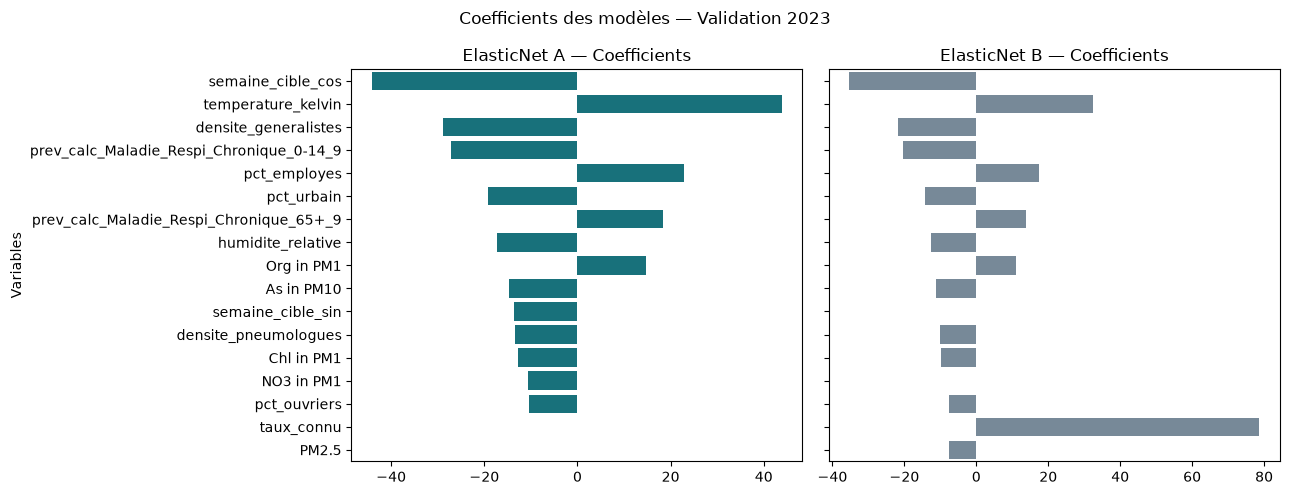

In [148]:
coefficients_A = coefficients_A.round(3)
coefficients_B = coefficients_B.round(3)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

sns.barplot(x = coefficients_A.values , y = coefficients_A.index, color="#087E8B", ax=axes[0], orient = "h")
axes[0].set_title("ElasticNet A — Coefficients") 

sns.barplot(x = coefficients_B.values , y = coefficients_B.index, color="#71899E", ax=axes[1], orient = "h")
axes[1].set_title("ElasticNet B — Coefficients")

for ax in axes:
    ax.set_ylabel("Variables")



fig.suptitle("Coefficients des modèles — Validation 2023")
plt.tight_layout()
plt.show()

## Verifcation / investigation

In [150]:
#je verifie les coeffs non nulls
print("Coefficients non nuls A :", np.sum(modele_A.coef_ != 0))
print("Coefficients non nuls B :", np.sum(modele_B.coef_ != 0))

Coefficients non nuls A : 111
Coefficients non nuls B : 103


In [151]:
#je regarde le coeff pour le taux_connu
coef_B = pd.Series(modele_B.coef_, index=X_train_B.columns)

print("Coefficient taux_connu :", coef_B["taux_connu"])

Coefficient taux_connu : 78.71319550082104


In [153]:
#correlation avec la cible (taux connu avec taux à predire
print("Corrélation avec la cible :",
      X_train_B["taux_connu"].corr(y_train))

print(X_train_B["taux_connu"].describe())

Corrélation avec la cible : 0.5365815075544242
count    9.888000e+03
mean    -2.558184e-16
std      1.000051e+00
min     -2.325765e+00
25%     -6.497083e-01
50%     -1.421468e-01
75%      4.823060e-01
max      8.929211e+00
Name: taux_connu, dtype: float64


In [154]:
# Corrélation entre le taux actuel et celui de la semaine suivante
train[["taux_connu", "taux_suivant"]].corr()

,taux_connu,taux_suivant
taux_connu,1.000000,0.536582
taux_suivant,0.536582,1.000000


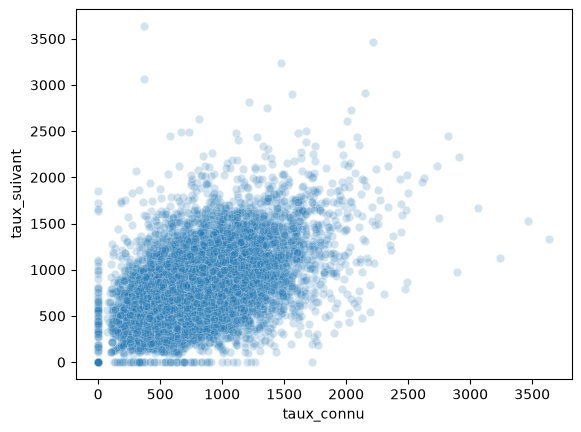

In [155]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=data,
    x="taux_connu",
    y="taux_suivant",
    alpha=0.2
)

plt.show()

Il y a une tendence positive, lors que taux_connu augmente, taux suivant augmente aussi. Mais il y a une ligne verticale x=0, maix y peut etre quand meme eleve, et y=0 mais taux connu peut etre elevé. 
Pour info, il y a des lignes 0, aucun valeur n'a pas ete remplace par 0 dans le fichier initiale

les points sont un paire semaine/departement

interessant: taux de la semaine actuelle 0 et la semaine suivante monte

In [156]:
#compter les observations 0
print("Taux connu = 0 :", (train["taux_connu"] == 0).sum())
print("Taux suivant = 0 :", (train["taux_suivant"] == 0).sum())

print("Taux connu = 0 et suivant > 0 :",
      ((train["taux_connu"] == 0) & (train["taux_suivant"] > 0)).sum())

print("Taux connu > 0 et suivant = 0 :",
      ((train["taux_connu"] > 0) & (train["taux_suivant"] == 0)).sum())

Taux connu = 0 : 45
Taux suivant = 0 : 43
Taux connu = 0 et suivant > 0 : 36
Taux connu > 0 et suivant = 0 : 34


In [157]:
# Comparer correlation pearson vs spearman

#relation linaire
print("Pearson :", train["taux_connu"].corr(
    train["taux_suivant"], method="pearson"))

#co-evolution sans relation parfaitement linaire
print("Spearman :", train["taux_connu"].corr(
    train["taux_suivant"], method="spearman"))

Pearson : 0.5365815075544244
Spearman : 0.5127297090179572


On observere quand meme un relation positive lineaire et modere entre le taux_connu et taux_suivante

In [158]:
from sklearn.linear_model import LinearRegression

modele_test = LinearRegression()

modele_test.fit(X_train_B[["taux_connu"]], y_train)

prediction_test = modele_test.predict(X_valid_B[["taux_connu"]])

afficher_scores("Régression taux connu seul", y_valid, prediction_test)

Régression taux connu seul
MAE  : 197.77
RMSE : 269.9
R²   : 0.303


La standardisation fonctionne : moyenne ≈ 0, écart-type ≈ 1.
taux_connu est informatif : utilisé seul, il explique environ 30 % de la variabilité des taux de 2023.
ElasticNet B l'ignore 

,Modèle,MAE,RMSE,R²
0,Persistance,219.03,306.11,0.104
1,Saisonnier,203.92,280.45,0.248
2,ElasticNet A,203.19,273.50,0.285
3,ElasticNet B,189.24,256.72,0.370


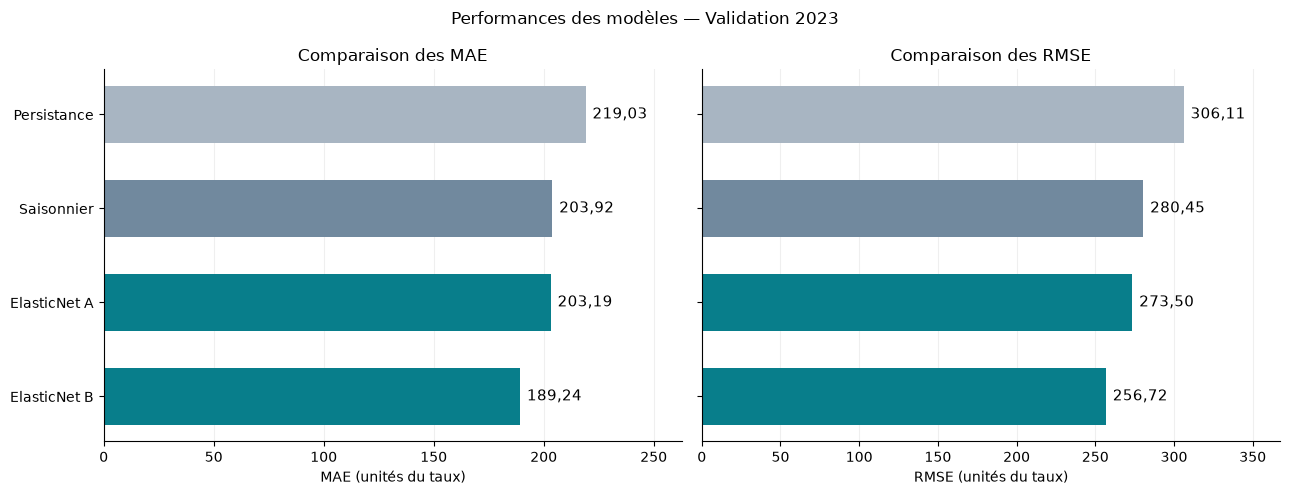

In [159]:
#Summary of results

#calculer les scores per modele
def calculer_scores(nom, reel, prediction):
    return {
        "Modèle": nom,
        "MAE": mean_absolute_error(reel, prediction),
        "RMSE": mean_squared_error(reel, prediction) ** 0.5,
        "R²": r2_score(reel, prediction)
    }

# construction du tableau   

scores = pd.DataFrame([
    calculer_scores("Persistance", y_valid, prediction_persistance),
    calculer_scores("Saisonnier", y_valid, prediction_saisonniere),
    calculer_scores("ElasticNet A", y_valid, prediction_A),
    calculer_scores("ElasticNet B", y_valid, prediction_B)
])

# Affichage arrondi, sans modifier les valeurs conservées
display(scores.round({"MAE": 2, "RMSE": 2, "R²": 3}))

#barplot
metrique = "MAE"  # ou "RMSE"
couleurs = ["#A8B5C2", "#71899E", "#087E8B", "#087E8B"]


fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, metrique in zip(axes, ["MAE", "RMSE"]):
    barres = ax.barh(
        scores["Modèle"],
        scores[metrique],
        color=couleurs,
        height=0.6
    )

    ax.bar_label(
        barres,
        labels=[
            f"{valeur:.2f}".replace(".", ",")
            for valeur in scores[metrique]
        ],
        padding=5,
        fontsize=11
    )

    ax.set_title(f"Comparaison des {metrique}")
    ax.set_xlabel(f"{metrique} (unités du taux)")

    maximum = scores[metrique].max()
    ax.set_xlim(0, maximum * 1.20 if maximum > 0 else 1)

    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

# Premier modèle en haut ; l'axe est partagé entre les deux graphiques
axes[0].invert_yaxis()

fig.suptitle("Performances des modèles — Validation 2023")
plt.tight_layout()
plt.show()

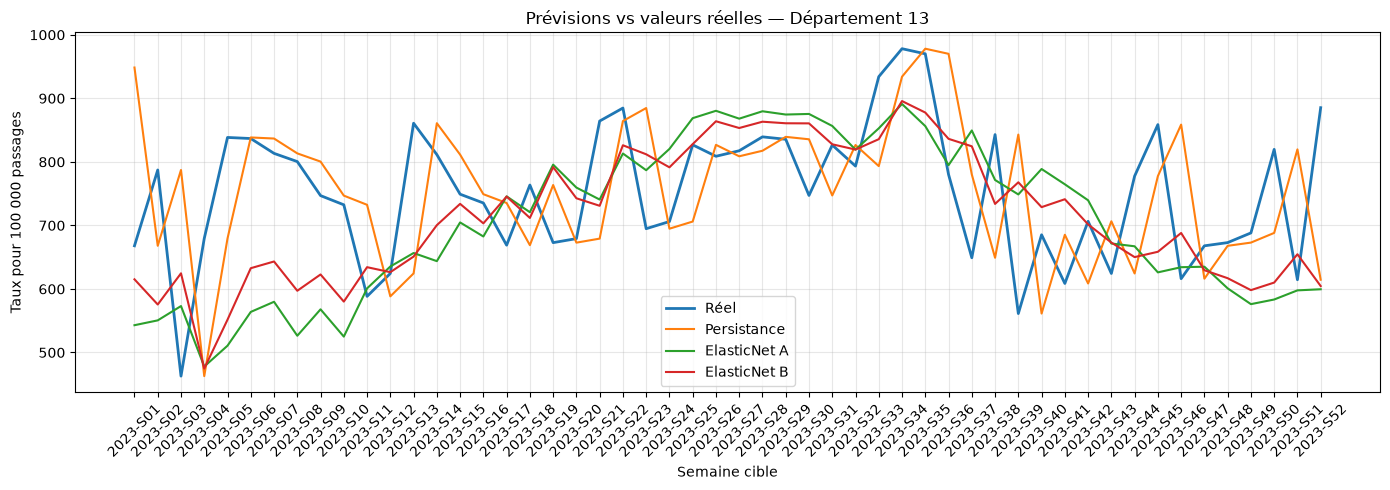

In [160]:
#comparaison reel vs prediction


# Choisir le département
dept = "13"

# Regrouper les prédictions
comparaison = valid[["code_dept", "semaine_a_prevoir"]].copy()

comparaison["Réel"] = y_valid
comparaison["Persistance"] = prediction_persistance
#comparaison["Moyenne historique"] = prediction_saisonniere
comparaison["ElasticNet A"] = prediction_A
comparaison["ElasticNet B"] = prediction_B

# Filtrer le département et trier les semaines
courbes = comparaison[comparaison["code_dept"] == dept].sort_values("semaine_a_prevoir")

# Graphique
plt.figure(figsize=(14, 5))

for col in ["Réel","Persistance", "ElasticNet A", "ElasticNet B"]:
    plt.plot(courbes["semaine_a_prevoir"], courbes[col],
             label=col, linewidth=2 if col == "Réel" else 1.5)

plt.title(f"Prévisions vs valeurs réelles — Département {dept}")
plt.xlabel("Semaine cible")
plt.ylabel("Taux pour 100 000 passages")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

on observe:
1. un décalage d'une semaine dans la prediction
2. le modele lisse les pics - pas adapté dans ce forme aux changements rapides

In [ ]:
# Comparaison des corrélations temporelles par département: Pour chaque département, nous calculons les corrélations de deux modèles avec cinq décalages différents.

resultats = []

for dept, groupe in comparaison.groupby("code_dept"):
    groupe = groupe.sort_values("semaine_a_prevoir")

    for modele in ["ElasticNet A", "ElasticNet B"]:
        for decalage in [-2, -1, 0, 1, 2]:

            corr = groupe[modele].corr(
                groupe["Réel"].shift(decalage)
            )

            resultats.append({
                "departement": dept,
                "modele": modele,
                "decalage": decalage,
                "correlation": corr
            })

df_corr = pd.DataFrame(resultats)

# Moyenne des corrélations sur tous les départements
resume = df_corr.groupby(
    ["modele", "decalage"]
)["correlation"].mean().unstack(0)

print(resume.round(3))

modele    ElasticNet A  ElasticNet B
decalage                            
-2               0.501         0.478
-1               0.523         0.516
 0               0.548         0.541
 1               0.562         0.821
 2               0.542         0.536


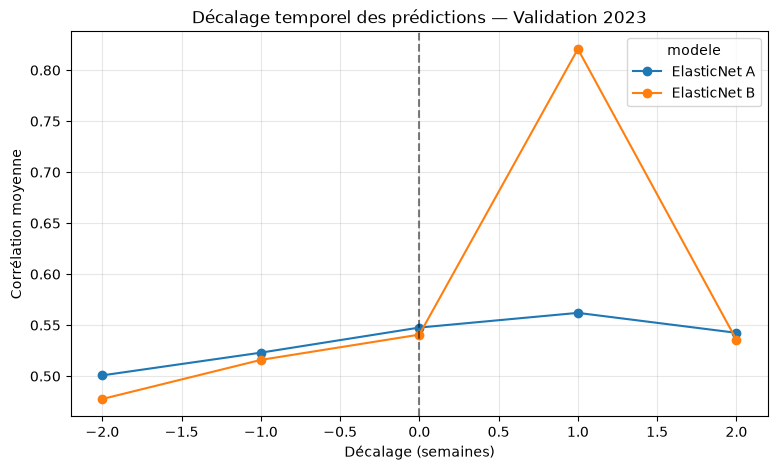

In [162]:
resume.plot(marker="o", figsize=(9, 5))

plt.axvline(0, color="black", linestyle="--", alpha=0.5)
plt.xlabel("Décalage (semaines)")
plt.ylabel("Corrélation moyenne")
plt.title("Décalage temporel des prédictions — Validation 2023")
plt.grid(alpha=0.3)
plt.show()

In [163]:
# Meilleur décalage pour chaque département et chaque modèle
meilleurs = df_corr.loc[
    df_corr.groupby(["departement", "modele"])["correlation"].idxmax()
]

print(pd.crosstab(
    meilleurs["decalage"],
    meilleurs["modele"]
))

modele    ElasticNet A  ElasticNet B
decalage                            
-2                   7             0
-1                   8             0
 0                  23             0
 1                  39            96
 2                  19             0
